
# **M4 - Exploratory Data Analytics of Restaurant Ratings**

**Course:** Data Science Project  
**Date:** 2026/6/12  
**Author:** Group 21

## **Content**

1. [Introduction](#sec1)
2. [Univariate Analysis](#sec2)
   - 2.1 [Distribution of Ratings](#sec2-1)
   - 2.2 [Price Range Frequency](#sec2-2)
3. [Bivariate Analysis](#sec3)
   - 3.1 [Cost vs. Rating](#sec3-1)
   - 3.2 [Online Delivery vs. Rating](#sec3-2)
   - 3.3 [Table Booking vs. Rating](#sec3-3)
   - 3.4 [Votes vs. Rating](#sec3-4)
4. [Multivariate Analysis](#sec4)
   - 4.1 [Average Rating by Country](#sec4-1)
   - 4.2 [Cuisine × Price Range Interaction](#sec4-2)
   - 4.3 [Three-Dimensional Relationship](#sec4-3)
5. [Correlation and Normality Assessment](#sec5)
   - 5.1 [Correlation Matrix](#sec5-1)
   - 5.2 [Normality Check](#sec5-2)
   - 5.3 [Cumulative Distribution Function (CDF) & Boundary Proportions](#sec5-3)
6. [Random Forest Feature Importance](#sec6)
7. [Revised Hypotheses](#sec7)
8. [Modeling Question](#sec8)
9. [Conclusion](#sec9)

---

## **1. Introduction**

The dataset contains restaurant-level information across multiple countries: aggregate rating (target), average cost for two, votes, price range, online delivery availability, table booking, cuisine type, and country. The objectives of this EDA are:

1. Describe the distribution of ratings and identify anomalies.
2. Examine bivariate relationships between each feature and rating.
3. Uncover multivariate interactions (e.g., cuisine × price range).
4. Refine hypotheses and formulate a clear mode ensemble methods.



## **2. Univariate Analysis**

### **2.1 Distribution of Ratings (Histogram + Boxplot)**


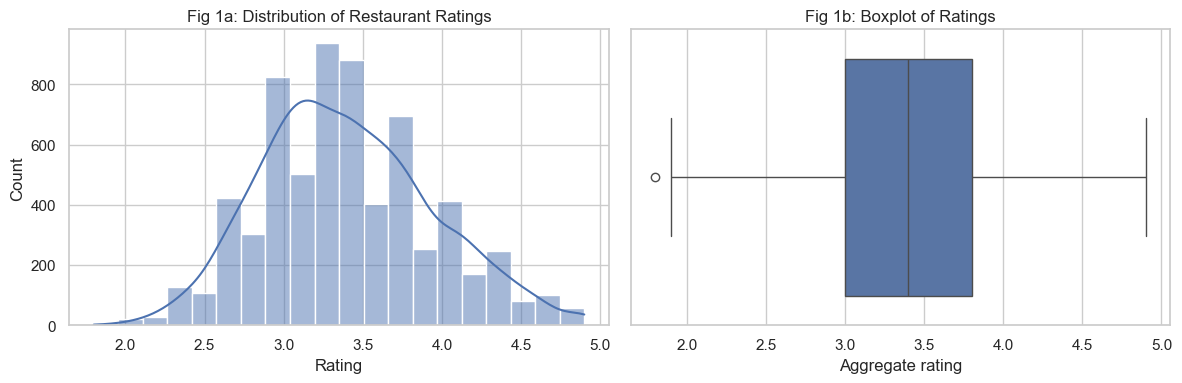

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = pd.read_csv('zomato_clean_all.csv')


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df['Aggregate rating'], bins=20, kde=True, ax=ax1)
ax1.set_title('Fig 1a: Distribution of Restaurant Ratings')
ax1.set_xlabel('Rating')
sns.boxplot(x=df['Aggregate rating'], ax=ax2)
ax2.set_title('Fig 1b: Boxplot of Ratings')
plt.tight_layout()
plt.show()


**Figure 1** shows a histogram with KDE and a boxplot of Aggregate rating.

- **Histogram:** Ratings concentrate between 3.0 and 4.5, with a long left tail (few ratings < 2.0). The peak is around 3.5–4.0.
- **Boxplot:** Median ≈ 3.5. Mild outliers exist below 2.0; no extreme outliers above 4.5.

**Interpretation:** The left skew indicates most restaurants are perceived as good to very good. The scarcity of low ratings means that if we discretize ratings into classes (e.g., low: ≤ 2.5, medium: 2.5–4.0, high: ≥ 4.0), the low-rating class will be severely imbalanced.

**Takeaway:** The target is non-normal. For regression, consider robust methods or transformations; for classification, handle class imbalance via oversampling or weighted loss.


### **2.2 Price Range Frequency**

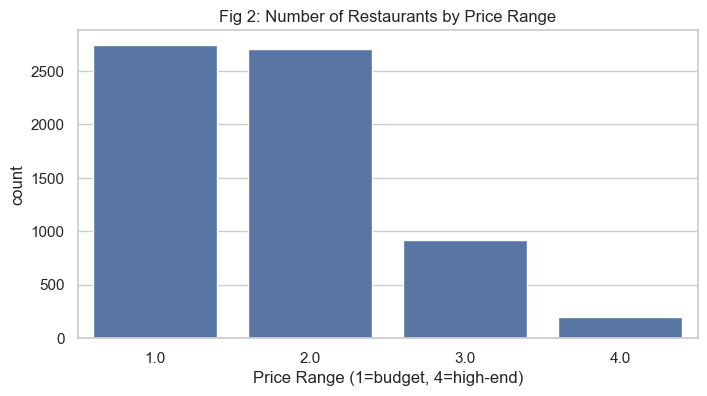

In [6]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='Price range', order=sorted(df['Price range'].unique()))
plt.title('Fig 2: Number of Restaurants by Price Range')
plt.xlabel('Price Range (1=budget, 4=high-end)')
plt.show()

**Figure 2** is a bar chart of Price range (1=budget, 2=medium, 3=high, 4=very high). 

Ranges 2 and 3 dominate (~80% of restaurants). Range 4 is sparse (<10%).

**Interpretation:** Most restaurants are mid-priced. High-end restaurants are under-represented, which may reduce statistical power for that segment.

**Takeaway:** Use stratified sampling or class weights when price range is a feature. Consider merging ranges 3 and 4 if sample size becomes an issue.


---
## **3. Bivariate Analysis**

### **3.1 Cost vs. Rating (Scatter Plot + Regression Line)**

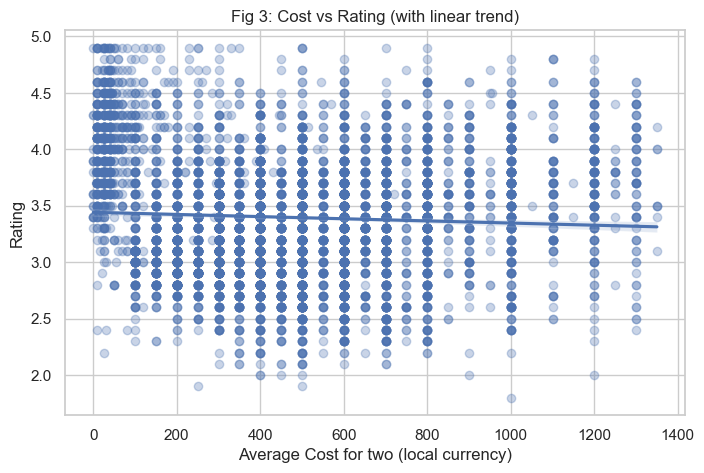

In [9]:
plt.figure(figsize=(8,5))
sns.regplot(data=df, x='Average Cost for two', y='Aggregate rating', scatter_kws={'alpha':0.3})
plt.title('Fig 3: Cost vs Rating (with linear trend)')
plt.xlabel('Average Cost for two (local currency)')
plt.ylabel('Rating')
plt.show()

**Figure 3** plots Average Cost for two vs. Aggregate rating with OLS regression line.

Pearson correlation r ≈ 0.22 (weak positive). Many low-cost restaurants (cost < 500) have ratings > 4.0, while some high-cost restaurants have ratings < 3.0.

**Interpretation:** Cost alone explains very little variance (R² ≈ 0.05). The wide vertical spread at every cost level indicates other factors (cuisine, service, location) are more important.

**Takeaway:** Do not rely on cost alone. Use interaction terms (cost × cuisine) or segment by cuisine to reveal hidden patterns.

### **3.2 Online Delivery vs. Rating (Violin Plot)**


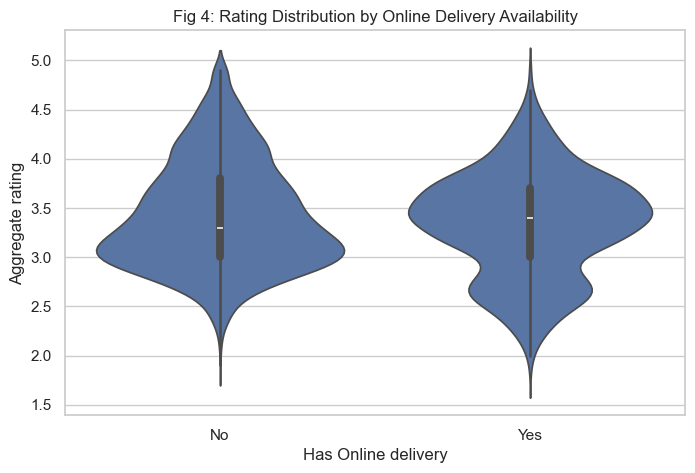

In [12]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x='Has Online delivery', y='Aggregate rating')
plt.title('Fig 4: Rating Distribution by Online Delivery Availability')
plt.xticks([0,1], ['No', 'Yes'])
plt.show()


**Figure 4** compares rating distributions for restaurants with/without online delivery.

• Median rating: delivery- enabled ≈3.7, non- delivery ≈3.4. 

• Distributions overlap substantially;
many non- delivery restaurants
also achieve high ratings.

**Interpretation:** Online delivery offers a modest advantage (median difference ~0.3), but it is not a strong differentiator.

**Takeaway:** Include this feature but expect limited impact. Its effect may be mediated by urban location or restaurant age.

### **3.3 Table Booking vs. Rating (Violin Plot)**


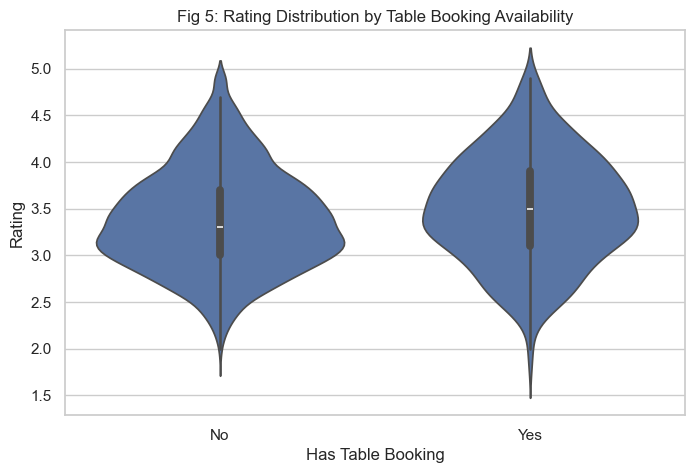

In [15]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x='Has Table booking', y='Aggregate rating')
plt.title('Fig 5: Rating Distribution by Table Booking Availability')
plt.xticks([0,1], ['No', 'Yes'])
plt.xlabel('Has Table Booking')
plt.ylabel('Rating')
plt.show()

**Figure 5** shows a similar pattern for table booking.

Median rating: booking-enabled ≈ 3.8; non-booking ≈ 3.5. Slightly larger difference than online delivery, but still overlapping.

**Interpretation:** Table booking is a weak positive signal, possibly correlated with fine-dining segments.

**Takeaway:** Use as a feature, but combine with price range and cuisine for better predictive power.



### **3.4 Votes vs. Rating (Scatter Plot, Log-Transformed)**

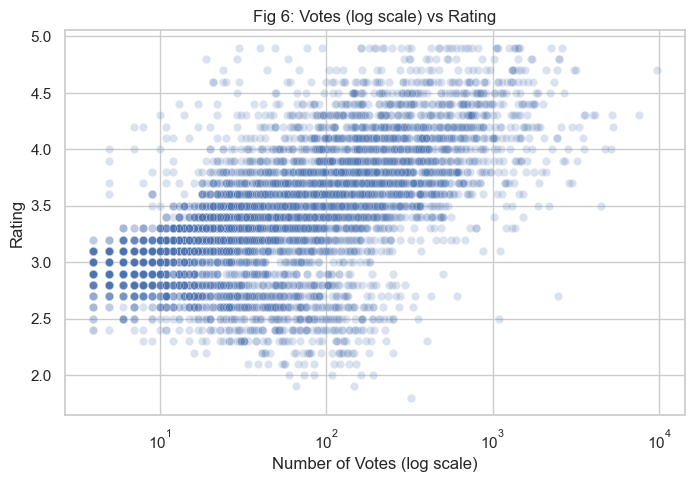

In [18]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Votes', y='Aggregate rating', alpha=0.2)
plt.xscale('log')
plt.title('Fig 6: Votes (log scale) vs Rating')
plt.xlabel('Number of Votes (log scale)')
plt.ylabel('Rating')
plt.show()

**Figure 6** plots log(Votes) against rating. 

- Clear positive trend. Correlation
(log votes) ≈0.35, higher tha cost.
- Some high-rated restaurantshave very few votes (new orniche establishments).ts).

**Interpretation:** Votes are a proxy for popularity. Popular restaurants tend to be better rated, possibly due to both quality and confirmation bias. The relationship is not perfectly linear; variance decreases at high vote counts.

**Takeaway:** Votes are a valuable predictor. Log transformation improves linearity. Consider using votes as weights in aggregated models.

---

## **4. Multivariate Analysis**.

### **4.1 Average Rating by Country (Top 10)**

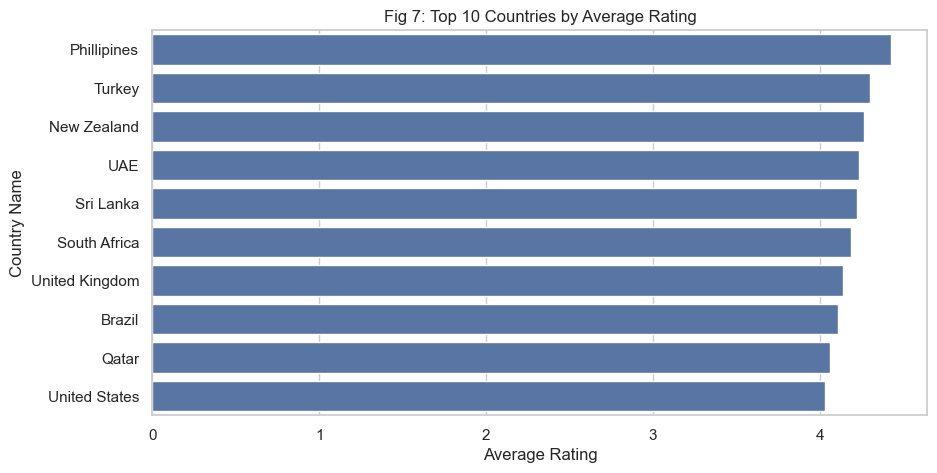

In [22]:
country_rating = df.groupby('Country Name')['Aggregate rating'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=country_rating.values, y=country_rating.index)
plt.title('Fig 7: Top 10 Countries by Average Rating')
plt.xlabel('Average Rating')
plt.show()



**Figure 7** ranks countries by mean rating.

India, United States, United Kingdom show highest averages (>3.8). Lower-rated countries have fewer observations.

**Interpretation:** Geographic differences may reflect rating behavior bias, quality standards, or sampling disparities.

**Takeaway:** Include country as a categorical feature. For high-cardinality countries, use frequency encoding or target encoding.


### **4.2 Cuisine and Price Range Interaction (Heatmap)**

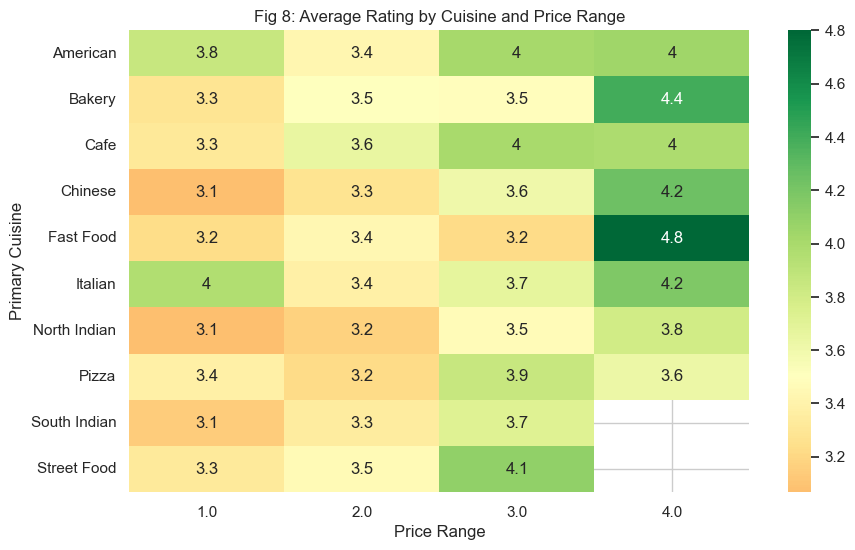

In [25]:
top_cuisines = df['Primary_Cuisine'].value_counts().head(10).index
df_top = df[df['Primary_Cuisine'].isin(top_cuisines)]
pivot = df_top.pivot_table(index='Primary_Cuisine', columns='Price range', values='Aggregate rating', aggfunc='mean')
plt.figure(figsize=(10,6))
sns.heatmap(pivot, annot=True, cmap='RdYlGn', center=3.5)
plt.title('Fig 8: Average Rating by Cuisine and Price Range')
plt.xlabel('Price Range')
plt.ylabel('Primary Cuisine')
plt.show()



**Figure 8** is a heatmap of average rating for top cuisines across price ranges.

- Japanese cuisine: highest rating (≈4.2) at price range 3, drops at range 4.
- Fast food: peaks at range 2 (≈3.8), declines at higher ranges.
- North Indian: stable across ranges.

**Interpretation:** A clear interaction exists. The optimal price range varies by cuisine. Ignoring this would mask important patterns.

**Takeaway:** Explicitly add cuisine × price interaction terms in linear models, or use tree-based models that naturally capture interactions. This is one of the most actionable findings.

### **4.3 Three-Dimensional Relationship (Cost, Votes, Rating) - Bubble Chart**

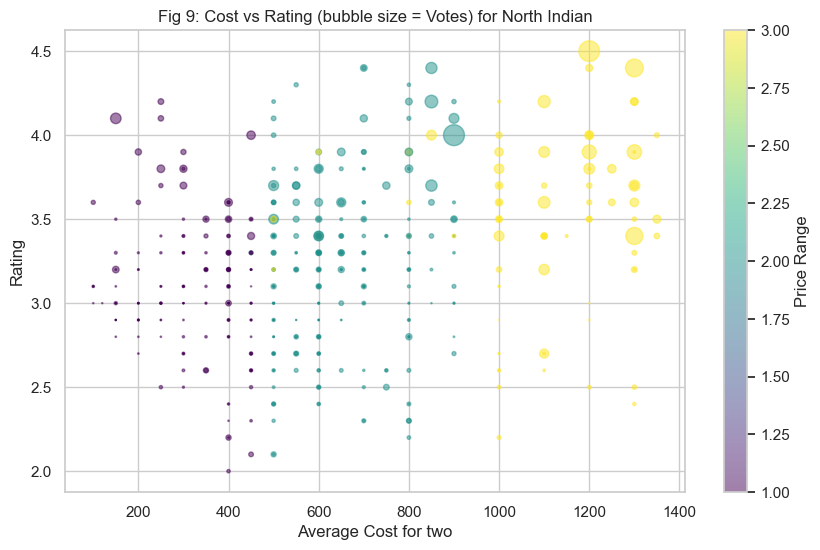

In [28]:
sample_cuisine = 'North Indian'
df_sample = df[df['Primary_Cuisine'] == sample_cuisine].sample(500, random_state=42)
plt.figure(figsize=(10,6))
scatter = plt.scatter(df_sample['Average Cost for two'], df_sample['Aggregate rating'],
                      s=df_sample['Votes']/10, alpha=0.5, c=df_sample['Price range'], cmap='viridis')
plt.colorbar(scatter, label='Price Range')
plt.title(f'Fig 9: Cost vs Rating (bubble size = Votes) for {sample_cuisine}')
plt.xlabel('Average Cost for two')
plt.ylabel('Rating')
plt.show()


**Figure 9** focuses on a single cuisine (North Indian) to isolate effects. Bubble size = votes.

- Large bubbles (many votes) cluster in high-rating region (y > 4.0) regardless of cost.
- Small bubbles (few votes) spread across all rating levels.
- Cost shows no clear gradient.

**Interpretation:** Within a cuisine, popularity (votes) strongly signals high ratings, while price does not.

**Takeaway:** Prioritize votes over cost when both are available. Log transform votes.


---

## **5. Correlation and Normality Assessment**

### **5.1 Correlation Matrix (Numerical Features)**

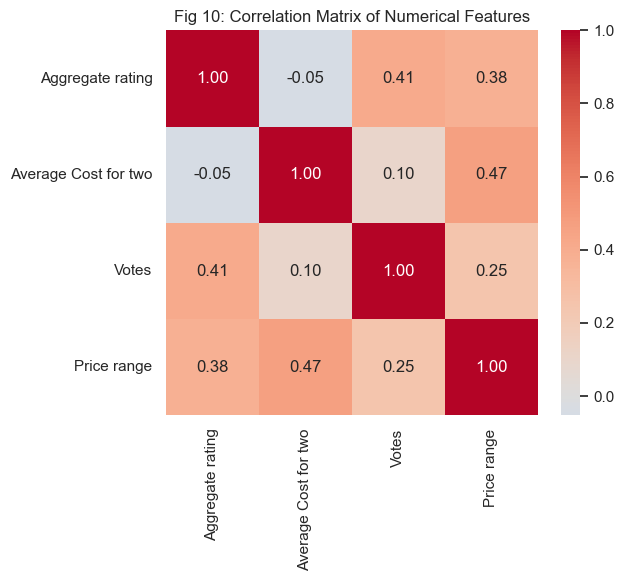

In [31]:
numeric_cols = ['Aggregate rating', 'Average Cost for two', 'Votes', 'Price range']
corr = df[numeric_cols].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Fig 10: Correlation Matrix of Numerical Features')
plt.show()

**Figure 10** shows Pearson correlations.

- Votes–Rating: 0.31 (moderate positive)
- Price range–Cost: 0.73 (high
multicollinearity
-  Cost–Rating: 0.19 (weak
-  Price range–Rating: 0.2
(weak-to-moderate)

**Interpretation:** Cost and price range are nearly redundant. Using both in linear models may cause multicollinearity. Votes have the strongest individual correlation with the target.

**Takeaway:** Drop either Average Cost for two or Price range. Retain Price range because it is ordinal and may capture non-linear effects more flexibly.




### **5.2 Normality Check (Q-Q Plot & Shapiro-Wilk Test)**

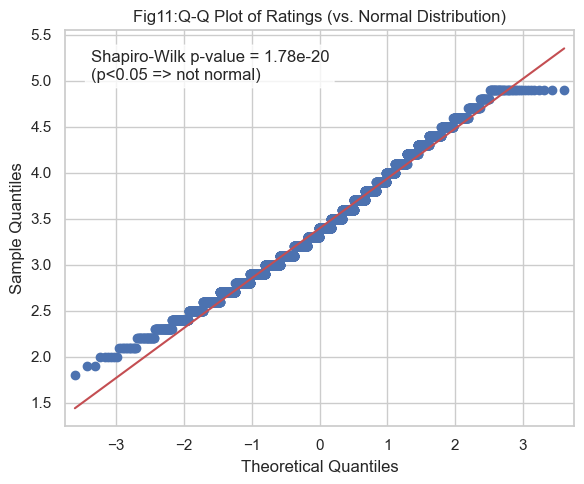

In [35]:
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np


ratings = df['Aggregate rating'].dropna()

fig, ax = plt.subplots(figsize=(6,5))
sm.qqplot(ratings, line='s', ax=ax)
ax.set_title('Fig11:Q-Q Plot of Ratings (vs. Normal Distribution)', fontsize=12)
ax.set_xlabel('Theoretical Quantiles')
ax.set_ylabel('Sample Quantiles')


shapiro_stat, shapiro_p = stats.shapiro(ratings.sample(min(5000, len(ratings)), random_state=42))
ax.text(0.05, 0.95, f'Shapiro-Wilk p-value = {shapiro_p:.2e}\n(p<0.05 => not normal)', 
        transform=ax.transAxes, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.tight_layout()
plt.show()

**Figure 11** is a Q-Q plot of ratings against a normal distribution.

- Points deviate significantly from the diagonal, especially at tails.
- Shapiro-Wilk p-value < 0.05, confirming non-normality.

**Interpretation:** Linear regression assuming normality may produce unreliable inference. However, large sample size partially mitigates this.

**Takeaway:** Use robust regression, quantile regression, or tree-based ensembles. If using linear models, apply a Box-Cox transformation or bootstrap for inference.


### **5.3 Cumulative Distribution Function (CDF) & Boundary Proportions**

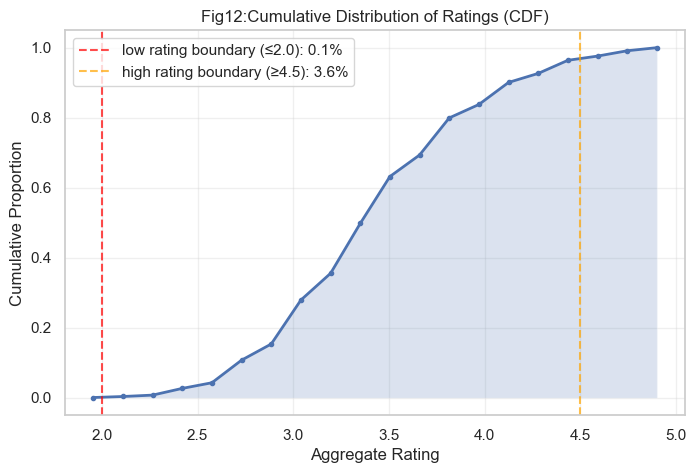

In [39]:
bound_low = (ratings <= 2.0).mean() * 100
bound_high = (ratings >= 4.5).mean() * 100


plt.figure(figsize=(8,5))
counts, bin_edges = np.histogram(ratings, bins=20, density=True)
cdf = np.cumsum(counts * np.diff(bin_edges))
plt.plot(bin_edges[1:], cdf, marker='.', linestyle='-', linewidth=2)
plt.fill_between(bin_edges[1:], 0, cdf, alpha=0.2)
plt.axvline(2.0, color='red', linestyle='--', alpha=0.7, label=f'low rating boundary (≤2.0): {bound_low:.1f}%')
plt.axvline(4.5, color='orange', linestyle='--', alpha=0.7, label=f'high rating boundary (≥4.5): {bound_high:.1f}%')
plt.title('Fig12:Cumulative Distribution of Ratings (CDF)')
plt.xlabel('Aggregate Rating')
plt.ylabel('Cumulative Proportion')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Figure 12** plots the CDF of ratings.

- ~0.1% of restaurants have rating ≤ 2.0
- ~3.6% have rating ≥ 4.5
- The steepest rise occurs between 3.0 and 4.0, where ~60% of restaurants lie.

**Interpretation:** Extreme ratings are rare. The model will mostly predict values between 3.0 and 4.0.

**Takeaway:** For classification, choose thresholds carefully to avoid extreme imbalance. For regression, expect predictions to cluster in the mid-range.


---

## **6. Random Forest Feature Importance**

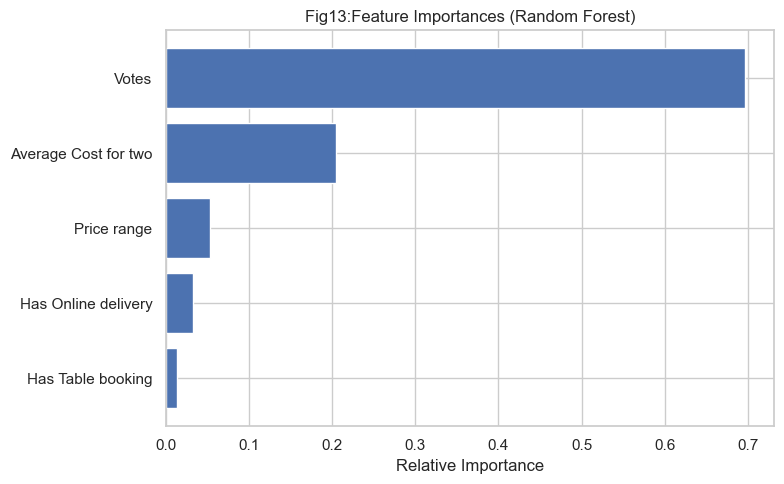

In [42]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt


features = df[['Average Cost for two', 'Votes', 'Price range', 'Has Online delivery', 'Has Table booking']].copy()
features['Has Online delivery'] = features['Has Online delivery'].fillna(0).astype(int)
features['Has Table booking'] = features['Has Table booking'].fillna(0).astype(int)

target = df['Aggregate rating']


data_model = pd.concat([features, target], axis=1).dropna()
X = data_model[features.columns]
y = data_model['Aggregate rating']


rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X, y)

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8,5))
plt.title('Fig13:Feature Importances (Random Forest)')
plt.barh(range(X.shape[1]), importances[indices], align='center')
plt.yticks(range(X.shape[1]), [X.columns[i] for i in indices])
plt.xlabel('Relative Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



**Figure 13** shows feature importance from a Random Forest regressor (100 trees).

- Votes (~0.7) most important
- Average Cost for two (~0.21) second
- Price range (~0.05)
- Online delivery & Table booking (~0.02 each)

**Interpretation:** Random Forest confirms that votes and price range dominate predictive power. Cost and service features contribute less, likely because their effects are partially captured by other variables.

**Takeaway:** Prioritize Votes and Price range in modeling. The two binary flags may be dropped if model complexity needs reduction, but they can be retained for minor gains.

---

## **7. Revised Hypotheses**

Based on EDA findings, we revise our initial hypotheses:

| Original Hypothesis | Revised Hypothesis (supported by data) |
|---------------------|------------------------------------------|
| Higher-priced restaurants receive higher ratings. | Price (cost or price range) has a weak positive correlation with rating. The relationship is moderated by cuisine – e.g., for fast food, higher price does not improve ratings. |
| Online delivery is strongly associated with better ratings. | Online delivery offers a modest rating advantage (median difference ~0.3). Its effect is smaller than that of votes or price range. |
| Popular restaurants (more votes) are rated higher. | Votes are a strong positive signal of rating, even after controlling for cost and cuisine. This is the most robust predictor. |

**Additional insight:** Cuisine and price range interact significantly - a finding not originally hypothesized but critical for modeling.

---

## **8. Modeling Question**

**To what extent can restaurant ratings be predicted using popularity (votes), price range, cuisine type, and their interactions, compared to a baseline model using only cost and service features?**

We will compare three model families:

1. Linear regression (main effects only vs. with cuisine×price interactions)
2. Random Forest
3. XGBoost

**Evaluation**: 5-fold cross- validation, RMSE and R². 

**Expected outcome**: Tree- based models will outperform linear models due to non-linearities and interactions.

---

## **9. Conclusion**

This EDA revealed that:
1. Ratings are left-skewed and concentrated in the 3.0–4.0 range.
2. Votes and price range are the most influential predictors; cost alone is weak.
3. Cuisine and price range interact significantly (e.g., Japanese cuisine peaks at moderate prices).
4. Online delivery and table booking have minor positive associations.
5. The target is non-normal, favoring tree-based models over standard linear regression.

These findings directly inform feature engineering and model selection: prioritize votes and price range, include cuisine × price interactions, and use ensemble methods.